# Regresión Logística con mentalidad de Red Neuronal

¡Bienvenido a tu primera asignación de programación (obligatoria)! Construirás un clasificador mediante regresión logística para reconocer gatos. Esta tarea te guiará paso a paso sobre cómo implementarlo con la mentalidad de una Red Neuronal, ayudándote a afinar tu intuición sobre Deep Learning.

**Instrucciones:**
- No uses bucles (for/while) en tu código, a menos que las instrucciones te lo pidan explícitamente.

**Aprenderás a:**
- Construir la arquitectura general de un algoritmo de aprendizaje, incluyendo:
    - Inicializar parámetros
    - Calcular la función de coste y su gradiente
    - Utilizar un algoritmo de optimización (descenso del gradiente) 
- Reunir las tres funciones anteriores en una función principal de modelo, en el orden correcto.

## <font color='darkblue'>Actualizaciones</font>
Este notebook se ha actualizado en los últimos meses. La versión anterior se llamaba "v5" y la actual es la "6a".

#### Si estabas trabajando en una versión previa:
* Podés encontrar tu trabajo anterior revisando el directorio de archivos para buscar las versiones más viejas.
* Para ver el directorio de archivos, hacé clic en el ícono de "Coursera" en la esquina superior izquierda de este notebook.
* Por favor copia tu trabajo de las versiones anteriores a la nueva versión para poder enviarlo y calificarlo.

#### Lista de Actualizaciones
* En la fórmula de propagación hacia adelante, la indexación ahora comienza en 1 en lugar de 0.
* El comentario de la función de optimización ahora dice "imprimir coste cada 100 iteraciones de entrenamiento" en lugar de "ejemplos".
* Se corrigió la gramática en los comentarios.
* El nombre de variable Y_prediction_test se utiliza de manera consistente.
* La etiqueta del eje del gráfico ahora dice "iteraciones (centenas)" en lugar de "iteraciones".
* Al evaluar el modelo, la imagen de prueba se normaliza dividiéndola por 255.

## 1 - Paquetes ##

Primero, ejecutemos la celda de abajo para importar todos los paquetes necesarios durante esta asignación.
- [numpy](www.numpy.org) es el paquete fundamental para computación científica con Python.
- [h5py](http://www.h5py.org) es un paquete común para interactuar con datasets almacenados en formato H5.
- [matplotlib](http://matplotlib.org) es una librería famosa para generar gráficos en Python.
- [PIL](http://www.pythonware.com/products/pil/) y [scipy](https://www.scipy.org/) se utilizan al final para probar el modelo con tu propia imagen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import scipy
from PIL import Image
from scipy import ndimage
from lr_utils import load_dataset

%matplotlib inline

## 2 - Visión general del problema ##

**Enunciado del problema**: Se te proporciona un conjunto de datos ("data.h5") que contiene:
    - un conjunto de entrenamiento de m_train imágenes etiquetadas como gato (y=1) o no-gato (y=0)
    - un conjunto de prueba de m_test imágenes etiquetadas como gato o no-gato
    - cada imagen tiene dimensiones (num_px, num_px, 3) donde 3 corresponde a los 3 canales (RGB). Por ende, cada imagen es cuadrada (alto = num_px) y (ancho = num_px).

Construirás un algoritmo simple de reconocimiento de imágenes que pueda clasificar correctamente si una foto es gato o no-gato.

Familiaricémonos con el dataset. Carga los datos ejecutando el siguiente código.

In [2]:
# Cargando los datos (gato/no-gato)
train_set_x_orig, train_set_y, test_set_x_orig, test_set_y, classes = load_dataset()

Agregamos "_orig" al final de los datasets de imágenes (train y test) porque vamos a preprocesarlos. Después del preprocesamiento, obtendremos train_set_x y test_set_x (las etiquetas train_set_y y test_set_y no necesitan ningún preprocesamiento).

Cada elemento de train_set_x_orig y test_set_x_orig es un arreglo que representa una imagen. Puedes visualizar un ejemplo ejecutando el siguiente código. Siéntete libre de cambiar el valor de `index` y volver a ejecutar para ver otras imágenes.

y = 0, es una imagen de tipo: 'non-cat'.


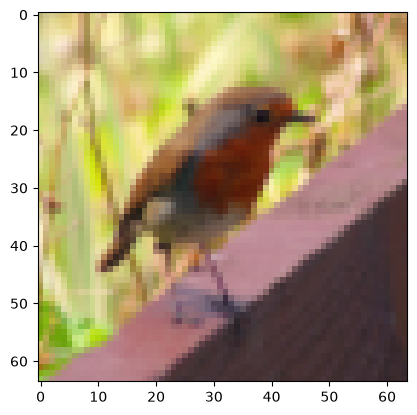

In [3]:
# Ejemplo de una imagen
index = 10
plt.imshow(train_set_x_orig[index])
print ("y = " + str(train_set_y[0, index]) + ", es una imagen de tipo: '" + classes[np.squeeze(train_set_y[:, index])].decode("utf-8") +  "'.")

Muchos errores de software en Deep Learning se deben a dimensiones de matrices/vectores incompatibles. Si mantienes las dimensiones consistentes y bajo control, evitarás gran parte de los bugs.

**Ejercicio:** Encuentra los valores para:
    - m_train (número de ejemplos de entrenamiento)
    - m_test (número de ejemplos de prueba)
    - num_px (= alto = ancho de una imagen de entrenamiento)
Recuerda que `train_set_x_orig` es un numpy-array de dimensiones (m_train, num_px, num_px, 3). Por ejemplo, puedes acceder a `m_train` escribiendo `train_set_x_orig.shape[0]`.

In [4]:
### COMIENZA TU CÓDIGO AQUÍ ### (≈ 3 líneas de código)
m_train = train_set_x_orig.shape[0]
m_test = test_set_x_orig.shape[0]
num_px = train_set_x_orig.shape[1]
### TERMINA TU CÓDIGO AQUÍ ###

print ("Número de ejemplos de entrenamiento: m_train = " + str(m_train))
print ("Número de ejemplos de prueba: m_test = " + str(m_test))
print ("Alto/Ancho de cada imagen: num_px = " + str(num_px))
print ("Cada imagen tiene dimensiones: (" + str(num_px) + ", " + str(num_px) + ", 3)")
print ("train_set_x shape: " + str(train_set_x_orig.shape))
print ("train_set_y shape: " + str(train_set_y.shape))
print ("test_set_x shape: " + str(test_set_x_orig.shape))
print ("test_set_y shape: " + str(test_set_y.shape))

Número de ejemplos de entrenamiento: m_train = 209
Número de ejemplos de prueba: m_test = 50
Alto/Ancho de cada imagen: num_px = 64
Cada imagen tiene dimensiones: (64, 64, 3)
train_set_x shape: (209, 64, 64, 3)
train_set_y shape: (1, 209)
test_set_x shape: (50, 64, 64, 3)
test_set_y shape: (1, 50)


**Salida Esperada para m_train, m_test y num_px**: 
<table style="width:15%">
  <tr>
    <td>**m_train**</td>
    <td> 209 </td> 
  </tr>
  
  <tr>
    <td>**m_test**</td>
    <td> 50 </td> 
  </tr>
  
  <tr>
    <td>**num_px**</td>
    <td> 64 </td> 
  </tr>
</table>


Por conveniencia, ahora debes redimensionar (reshape) las imágenes de dimensiones (num_px, num_px, 3) a un numpy-array de dimensiones (num_px $*$ num_px $*$ 3, 1). Después de esto, nuestro conjunto de entrenamiento (y prueba) será un arreglo de NumPy donde cada columna representará una imagen aplanada (*flattened*). Habrá m_train (y m_test respectivamente) columnas.

**Ejercicio:** Redimensiona los conjuntos de datos de entrenamiento y prueba para que las imágenes de tamaño (num_px, num_px, 3) queden aplanadas en vectores individuales de dimensiones (num\_px $*$ num\_px $*$ 3, 1).

Un truco cuando quieres aplanar una matriz X de dimensiones (a, b, c, d) a una matriz X_flatten de dimensiones (b$*$c$*$d, a) es usar: 
```python
X_flatten = X.reshape(X.shape[0], -1).T      # X.T es la transpuesta de X
```

In [5]:
# Redimensionar los ejemplos de entrenamiento y prueba

### COMIENZA TU CÓDIGO AQUÍ ### (≈ 2 líneas de código)
train_set_x_flatten = train_set_x_orig.reshape(train_set_x_orig.shape[0], -1).T
test_set_x_flatten = test_set_x_orig.reshape(test_set_x_orig.shape[0], -1).T
### TERMINA TU CÓDIGO AQUÍ ###

print ("train_set_x_flatten shape: " + str(train_set_x_flatten.shape))
print ("train_set_y shape: " + str(train_set_y.shape))
print ("test_set_x_flatten shape: " + str(test_set_x_flatten.shape))
print ("test_set_y shape: " + str(test_set_y.shape))
print ("comprobación post redimensionado: " + str(train_set_x_flatten[0:5,0]))

train_set_x_flatten shape: (12288, 209)
train_set_y shape: (1, 209)
test_set_x_flatten shape: (12288, 50)
test_set_y shape: (1, 50)
comprobación post redimensionado: [17 31 56 22 33]


**Salida Esperada**: 

<table style="width:35%">
  <tr>
    <td>**train_set_x_flatten shape**</td>
    <td> (12288, 209)</td> 
  </tr>
  <tr>
    <td>**train_set_y shape**</td>
    <td>(1, 209)</td> 
  </tr>
  <tr>
    <td>**test_set_x_flatten shape**</td>
    <td>(12288, 50)</td> 
  </tr>
  <tr>
    <td>**test_set_y shape**</td>
    <td>(1, 50)</td> 
  </tr>
  <tr>
  <td>**comprobación post redimensionado**</td>
  <td>[17 31 56 22 33]</td> 
  </tr>
</table>

Para representar imágenes a color, se deben especificar los canales rojo, verde y azul (RGB) para cada píxel, por lo que el valor de un píxel es un vector de tres números que van de 0 a 255.

Un paso de preprocesamiento estándar en Machine Learning es centrar y estandarizar el conjunto de datos, restando la media del arreglo y dividiendo por la desviación estándar. En el caso de imágenes, es mucho más simple y conveniente (y funciona prácticamente igual de bien) dividir cada fila por 255 (el valor máximo posible de un canal de píxel).

Estandaricemos nuestro conjunto de datos.

In [6]:
train_set_x = train_set_x_flatten/255.
test_set_x = test_set_x_flatten/255.

<font color='blue'>
**Puntos clave para recordar:**

Los pasos comunes para preprocesar un nuevo conjunto de datos son:
- Determinar las dimensiones y formas del problema (m_train, m_test, num_px, ...)
- Redimensionar los datasets para que cada ejemplo sea un vector de tamaño (num_px \* num_px \* 3, 1)
- "Estandarizar" los datos

## 3 - Arquitectura General del algoritmo de aprendizaje ##

Es hora de diseñar un algoritmo simple para distinguir fotos de gatos de las que no lo son.

Construirás una Regresión Logística utilizando la mentalidad de una Red Neuronal. ¡La siguiente figura muestra por qué **la Regresión Logística es en realidad una Red Neuronal muy simple!**

<img src="images/LogReg_kiank.png" style="width:650px;height:400px;">

**Expresión matemática del algoritmo**:

Para un ejemplo individual $x^{(i)}$:
$$z^{(i)} = w^T x^{(i)} + b \tag{1}$$
$$\hat{y}^{(i)} = a^{(i)} = sigmoid(z^{(i)})\tag{2}$$ 
$$ \mathcal{L}(a^{(i)}, y^{(i)}) =  - y^{(i)}  \log(a^{(i)}) - (1-y^{(i)} )  \log(1-a^{(i)})\tag{3}$$

El coste global se calcula sumando sobre todos los ejemplos de entrenamiento:
$$ J = \frac{1}{m} \sum_{i=1}^m \mathcal{L}(a^{(i)}, y^{(i)})\tag{6}$$

**Pasos clave**:
En este ejercicio, llevarás a cabo los siguientes pasos: 
    - Inicializar los parámetros del modelo
    - Aprender los parámetros minimizando el coste  
    - Usar los parámetros aprendidos para hacer predicciones (sobre el conjunto de prueba)
    - Analizar los resultados y concluir

## 4 - Construyendo las partes de nuestro algoritmo ## 

Los pasos principales para construir una Red Neuronal son:
1. Definir la estructura del modelo (como la cantidad de características de entrada) 
2. Inicializar los parámetros del modelo
3. Bucle (*Loop*):
    - Calcular la pérdida actual (propagación hacia adelante / forward propagation)
    - Calcular el gradiente actual (propagación hacia atrás / backward propagation)
    - Actualizar los parámetros (descenso del gradiente)

Generalmente se construyen los pasos 1-3 por separado y luego se integran en una función principal que llamaremos `model()`.

### 4.1 - Funciones auxiliares

**Ejercicio**: Implementa la función `sigmoid()`. Como viste en la figura anterior, necesitas calcular $sigmoid( w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}$ para realizar predicciones. Usa `np.exp()`.

In [7]:
# FUNCIÓN EVALUADA: sigmoid

def sigmoid(z):
    """
    Calcula la sigmoide de z

    Argumentos:
    z -- Un escalar o arreglo numpy de cualquier tamaño.

    Retorna:
    s -- sigmoid(z)
    """

    ### COMIENZA TU CÓDIGO AQUÍ ### (≈ 1 línea de código)
    s = 1 / (1+ np.exp(-z))
    ### TERMINA TU CÓDIGO AQUÍ ###
    
    return s

In [8]:
print ("sigmoid([0, 2]) = " + str(sigmoid(np.array([0,2]))))

sigmoid([0, 2]) = [0.5        0.88079708]


**Salida Esperada**: 

<table>
  <tr>
    <td>**sigmoid([0, 2])**</td>
    <td> [ 0.5         0.88079708]</td> 
  </tr>
</table>

### 4.2 - Inicialización de parámetros

**Ejercicio:** Implementa la inicialización de parámetros en la celda de abajo. Debes inicializar w como un vector de ceros. Si no sabes qué función de numpy usar, busca `np.zeros()` en la documentación de NumPy.

In [24]:
# FUNCIÓN EVALUADA: initialize_with_zeros

def initialize_with_zeros(dim):
    """
    Esta función crea un vector de ceros de dimensiones (dim, 1) para w e inicializa b a 0.
    
    Argumento:
    dim -- tamaño deseado del vector w (número de parámetros en este caso)
    
    Retorna:
    w -- vector inicializado de dimensiones (dim, 1)
    b -- escalar inicializado a 0 (sesgo / bias)
    """
    
    ### COMIENZA TU CÓDIGO AQUÍ ### (≈ 1 línea de código)
    w = np.zeros((dim,1)) ### MATRIZ dim x 1 ###
    b = 0
    ### TERMINA TU CÓDIGO AQUÍ ###

    assert(w.shape == (dim, 1))
    assert(isinstance(b, float) or isinstance(b, int))
    
    return w, b

In [25]:
dim = 2
w, b = initialize_with_zeros(dim)
print ("w = " + str(w))
print ("b = " + str(b))

w = [[0.]
 [0.]]
b = 0


**Salida Esperada**: 

<table style="width:15%">
    <tr>
        <td>  ** w **  </td>
        <td> [[ 0.]
 [ 0.]] </td>
    </tr>
    <tr>
        <td>  ** b **  </td>
        <td> 0 </td>
    </tr>
</table>

Para entradas de imágenes, w tendrá dimensiones (num_px $\times$ num_px $\times$ 3, 1).

### 4.3 - Propagación hacia adelante y hacia atrás (Forward y Backward propagation)

Ahora que tus parámetros están inicializados, puedes ejecutar los pasos de propagación hacia adelante y hacia atrás para aprender los parámetros.

**Ejercicio:** Implementa una función `propagate()` que calcule la función de coste y su gradiente.

**Pistas**:

Propagación hacia adelante (Forward):
- Recibes X
- Calculas $A = \sigma(w^T X + b) = (a^{(1)}, a^{(2)}, ..., a^{(m-1)}, a^{(m)})$
- Calculas la función de coste: $J = -\frac{1}{m}\sum_{i=1}^{m}y^{(i)}\log(a^{(i)})+(1-y^{(i)})\log(1-a^{(i)})$

Aquí tienes las dos fórmulas que utilizarás: 

$$ \frac{\partial J}{\partial w} = \frac{1}{m}X(A-Y)^T\tag{7}$$
$$ \frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (a^{(i)}-y^{(i)})\tag{8}$$

In [31]:
# FUNCIÓN EVALUADA: propagate
def propagate(w, b, X, Y):
    """
    Implementa la función de coste y su gradiente para la propagación explicada arriba

    Argumentos:
    w -- pesos, un arreglo numpy de tamaño (num_px * num_px * 3, 1)
    b -- sesgo, un escalar
    X -- datos de dimensiones (num_px * num_px * 3, número de ejemplos)
    Y -- vector con la etiqueta real (0 si es no-gato, 1 si es gato) de tamaño (1, número de ejemplos)

    Retorna:
    cost -- coste negativo de verosimilitud logarítmica para regresión logística
    dw -- gradiente de la pérdida respecto a w, con las mismas dimensiones que w
    db -- gradiente de la pérdida respecto a b, con las mismas dimensiones que b
    
    Consejos:
    - Escribe tu código paso a paso para la propagación. np.log(), np.dot()
    """
    
    m = X.shape[1]
    
    # PROPAGACIÓN HACIA ADELANTE (DE X AL COSTE)
    ### COMIENZA TU CÓDIGO AQUÍ ### (≈ 2 líneas de código)
    A = sigmoid(np.dot(w.T, X) + b)
    cost = (1/m) * np.sum(-(np.multiply(Y, np.log(A)) + np.multiply((1 - Y), np.log(1 -A))))
    ### TERMINA TU CÓDIGO AQUÍ ###
    
    # PROPAGACIÓN HACIA ATRÁS (PARA HALLAR GRADIENTES)
    ### COMIENZA TU CÓDIGO AQUÍ ### (≈ 2 líneas de código)
    dw = (1/m) * np.dot(X, (A-Y).T)
    db = (1/m) * np.sum((A-Y))
    ### TERMINA TU CÓDIGO AQUÍ ###

    assert(dw.shape == w.shape)
    assert(db.dtype == float)
    cost = np.squeeze(cost)
    assert(cost.shape == ())
    
    grads = {"dw": dw,
             "db": db}
    
    return grads, cost

In [32]:
w, b, X, Y = np.array([[1.],[2.]]), 2., np.array([[1.,2.,-1.],[3.,4.,-3.2]]), np.array([[1,0,1]])
grads, cost = propagate(w, b, X, Y)
print ("dw = " + str(grads["dw"]))
print ("db = " + str(grads["db"]))
print ("cost = " + str(cost))

dw = [[0.99845601]
 [2.39507239]]
db = 0.001455578136784208
cost = 5.801545319394553


**Salida Esperada**:

<table style="width:50%">
    <tr>
        <td>  ** dw **  </td>
      <td> [[ 0.99845601]
     [ 2.39507239]]</td>
    </tr>
    <tr>
        <td>  ** db **  </td>
        <td> 0.00145557813678 </td>
    </tr>
    <tr>
        <td>  ** cost **  </td>
        <td> 5.801545319394553 </td>
    </tr>
</table>

### 4.4 - Optimización
- Has inicializado tus parámetros.
- Ya puedes calcular la función de coste y sus gradientes.
- Ahora debes actualizar los parámetros utilizando el descenso del gradiente.

**Ejercicio:** Escribe la función de optimización. El objetivo es aprender $w$ y $b$ minimizando la función de coste $J$. Para un parámetro $\theta$, la regla de actualización es $ \theta = \theta - \alpha \text{ } d\theta$, donde $\alpha$ es la tasa de aprendizaje (*learning rate*).

In [38]:
# FUNCIÓN EVALUADA: optimize

def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    """
    Esta función optimiza w y b ejecutando el algoritmo de descenso del gradiente
    
    Argumentos:
    w -- pesos, un arreglo numpy de tamaño (num_px * num_px * 3, 1)
    b -- sesgo, un escalar
    X -- datos de dimensiones (num_px * num_px * 3, número de ejemplos)
    Y -- vector con la etiqueta real (0 si es no-gato, 1 si es gato), de dimensiones (1, número de ejemplos)
    num_iterations -- número de iteraciones del bucle de optimización
    learning_rate -- tasa de aprendizaje utilizada en la regla de actualización
    print_cost -- True para imprimir el coste cada 100 pasos
    
    Retorna:
    params -- diccionario con los pesos w y el sesgo b
    grads -- diccionario con los gradientes de w y b respecto a la función de coste
    costs -- lista con todos los costes calculados durante la optimización, usada para graficar la curva de aprendizaje.
    
    Consejos:
    Básicamente debes escribir dos pasos e iterar sobre ellos:
        1) Calcular el coste y el gradiente para los parámetros actuales. Usa propagate().
        2) Actualizar los parámetros con la regla del descenso del gradiente para w y b.
    """
    
    costs = []
    
    for i in range(num_iterations):
        
        # Cálculo de coste y gradientes (≈ 1-4 líneas de código)
        ### COMIENZA TU CÓDIGO AQUÍ ### 
        grads, cost = propagate(w,b,X,Y)
        ### TERMINA TU CÓDIGO AQUÍ ###
        
        # Obtener derivadas desde grads
        dw = grads["dw"]
        db = grads["db"]
        
        # Regla de actualización (≈ 2 líneas de código)
        ### COMIENZA TU CÓDIGO AQUÍ ###
        w = w - (learning_rate * dw)
        b = b - (learning_rate * db)
        ### TERMINA TU CÓDIGO AQUÍ ###
        
        # Guardar los costes
        if i % 100 == 0:
            costs.append(cost)
        
        # Imprimir el coste cada 100 iteraciones de entrenamiento
        if print_cost and i % 100 == 0:
            print ("Coste tras la iteración %i: %f" %(i, cost))
    
    params = {"w": w,
              "b": b}
    
    grads = {"dw": dw,
             "db": db}
    
    return params, grads, costs

In [39]:
params, grads, costs = optimize(w, b, X, Y, num_iterations= 100, learning_rate = 0.009, print_cost = False)

print ("w = " + str(params["w"]))
print ("b = " + str(params["b"]))
print ("dw = " + str(grads["dw"]))
print ("db = " + str(grads["db"]))

w = [[0.19033591]
 [0.12259159]]
b = 1.9253598300845747
dw = [[0.67752042]
 [1.41625495]]
db = 0.21919450454067652


In [ ]:
import matplotlib.pyplot as plt
plt.plot(costs)

**Salida Esperada**: 
<table style="width:40%">
    <tr>
       <td> **w** </td>
       <td>[[ 0.19033591] [ 0.12259159]] </td>
    </tr>
    <tr>
       <td> **b** </td>
       <td> 1.92535983008 </td>
    </tr>
    <tr>
       <td> **dw** </td>
       <td> [[ 0.67752042]
 [ 1.41625495]] </td>
    </tr>
    <tr>
       <td> **db** </td>
       <td> 0.219194504541 </td>
    </tr>
</table>

**Ejercicio:** La función anterior devolverá los valores aprendidos de w y b. Ahora podemos usar w y b para predecir las etiquetas de un conjunto de datos X. Implementa la función `predict()`. Hay dos pasos para calcular las predicciones:

1. Calcular $\hat{Y} = A = \sigma(w^T X + b)$

2. Convertir las entradas de a en 0 (si la activación <= 0.5) o en 1 (si la activación > 0.5), y almacenar las predicciones en un vector `Y_prediction`. Si deseas, puedes usar un condicional `if`/`else` dentro de un bucle `for` (aunque también hay formas de vectorizarlo).

In [ ]:
# FUNCIÓN EVALUADA: predict

def predict(w, b, X):
    '''
    Predice si la etiqueta es 0 o 1 usando los parámetros aprendidos de regresión logística (w, b)
    
    Argumentos:
    w -- pesos, un arreglo numpy de tamaño (num_px * num_px * 3, 1)
    b -- sesgo, un escalar
    X -- datos de dimensiones (num_px * num_px * 3, número de ejemplos)
    
    Retorna:
    Y_prediction -- un arreglo numpy (vector) con todas las predicciones (0/1) para los ejemplos en X
    '''
    
    m = X.shape[1]
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1)
    
    # Calcular el vector "A" que predice las probabilidades de que haya un gato en la imagen
    ### COMIENZA TU CÓDIGO AQUÍ ### (≈ 1 línea de código)
    A = None
    ### TERMINA TU CÓDIGO AQUÍ ###
    
    for i in range(A.shape[1]):
        # Convertir probabilidades A[0,i] a predicciones p[0,i]
        ### COMIENZA TU CÓDIGO AQUÍ ### (≈ 4 líneas de código)
        pass
        ### TERMINA TU CÓDIGO AQUÍ ###
    
    assert(Y_prediction.shape == (1, m))
    
    return Y_prediction

In [ ]:
w = np.array([[0.1124579],[0.23106775]])
b = -0.3
X = np.array([[1.,-1.1,-3.2],[1.2,2.,0.1]])
print ("predicciones = " + str(predict(w, b, X)))

**Salida Esperada**: 

<table style="width:30%">
    <tr>
         <td>
             **predicciones**
         </td>
          <td>
            [[ 1.  1.  0.]]
         </td>  
   </tr>
</table>


<font color='blue'>
**Puntos a recordar:**
Has implementado varias funciones que:
- Inicializan (w, b)
- Optimizan la pérdida iterativamente para aprender los parámetros (w, b):
    - calculando el coste y su gradiente 
    - actualizando los parámetros usando descenso del gradiente
- Utilizan (w, b) aprendidos para predecir las etiquetas de nuevos ejemplos

## 5 - Integrar todas las funciones en un modelo ##

Ahora verás cómo se estructura el modelo global ensamblando todos los bloques constructivos (funciones implementadas en las secciones previas) en el orden adecuado.

**Ejercicio:** Implementa la función general `model()`. Usa la siguiente notación:
    - Y_prediction_test para tus predicciones sobre el conjunto de test
    - Y_prediction_train para tus predicciones sobre el conjunto de train
    - w, costs, grads para las salidas de optimize()

In [ ]:
# FUNCIÓN EVALUADA: model

def model(X_train, Y_train, X_test, Y_test, num_iterations = 2000, learning_rate = 0.5, print_cost = False):
    """
    Construye el modelo de regresión logística llamando a las funciones implementadas previamente
    
    Argumentos:
    X_train -- conjunto de entrenamiento representado por un numpy-array de dimensiones (num_px * num_px * 3, m_train)
    Y_train -- etiquetas de entrenamiento representadas por un numpy-array de dimensiones (1, m_train)
    X_test -- conjunto de prueba representado por un numpy-array de dimensiones (num_px * num_px * 3, m_test)
    Y_test -- etiquetas de prueba representadas por un numpy-array de dimensiones (1, m_test)
    num_iterations -- hiperparámetro que representa la cantidad de iteraciones para optimizar
    learning_rate -- hiperparámetro que representa la tasa de aprendizaje en la regla de actualización de optimize()
    print_cost -- True para imprimir el coste cada 100 iteraciones
    
    Retorna:
    d -- diccionario con información sobre el modelo entrenado.
    """
    
    ### COMIENZA TU CÓDIGO AQUÍ ###
    
    # inicializar parámetros con ceros (≈ 1 línea de código)
    w, b = None, None

    # Descenso del gradiente (≈ 1 línea de código)
    parameters, grads, costs = None, None, None
    
    # Recuperar w y b del diccionario "parameters"
    w = None
    b = None
    
    # Predecir sobre los ejemplos de test/train (≈ 2 líneas de código)
    Y_prediction_test = None
    Y_prediction_train = None
    ### TERMINA TU CÓDIGO AQUÍ ###

    # Imprimir precisión en Train y Test
    print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100))
    print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100))

    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test, 
         "Y_prediction_train" : Y_prediction_train, 
         "w" : w, 
         "b" : b,
         "learning_rate" : learning_rate,
         "num_iterations": num_iterations}
    
    return d

Ejecuta la siguiente celda para entrenar tu modelo.

In [ ]:
d = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations = 2000, learning_rate = 0.005, print_cost = False)

**Salida Esperada**: 
<table style="width:40%"> 
    <tr>
        <td> **Coste tras iteración 0 **  </td> 
        <td> 0.693147 </td>
    </tr>
      <tr>
        <td> <center> $\vdots$ </center> </td> 
        <td> <center> $\vdots$ </center> </td> 
    </tr>  
    <tr>
        <td> **Precisión en Train**  </td> 
        <td> 99.04306220095694 % </td>
    </tr>
    <tr>
        <td>**Precisión en Test** </td> 
        <td> 70.0 % </td>
    </tr>
</table> 

**Comentario**: La precisión de entrenamiento se acerca al 100%. Esta es una buena comprobación de sanidad: tu modelo funciona y tiene suficiente capacidad para ajustarse a los datos de entrenamiento. La precisión de prueba es del 68-70%. No está nada mal para este modelo simple, dado el pequeño dataset que usamos y considerando que la regresión logística es un clasificador puramente lineal. ¡Pero no te preocupes, construirás un clasificador mucho más potente la próxima semana!

Además, puedes ver que el modelo sobreajusta (*overfitting*) los datos de entrenamiento. Más adelante en la especialización aprenderás cómo mitigar el sobreajuste (por ejemplo mediante regularización). Usando el código de abajo (y cambiando el valor de la variable `index`) puedes ver las predicciones en las imágenes del conjunto de prueba.

In [ ]:
# Ejemplo de una imagen clasificada
index = 25
plt.imshow(test_set_x[:,index].reshape((num_px, num_px, 3)))
print ("y = " + str(test_set_y[0,index]) + ", tu predicción indica que es una foto de tipo \"" + classes[int(d["Y_prediction_test"][0,index])].decode("utf-8") +  "\".")

Grafiquemos también la función de coste.

In [40]:
# Graficar curva de aprendizaje (con costes)
costs = np.squeeze(d['costs'])
plt.plot(costs)
plt.ylabel('coste')
plt.xlabel('iteraciones (en centenas)')
plt.title("Tasa de aprendizaje =" + str(d["learning_rate"]))
plt.show()

NameError: name 'd' is not defined

**Interpretación**:
Puedes ver cómo el coste decrece de manera constante. Esto demuestra que los parámetros se están aprendiendo correctamente. Sin embargo, podrías entrenar aún más el modelo en el conjunto de entrenamiento. Intenta aumentar el número de iteraciones y vuelve a ejecutar. Podrás notar que la precisión en el conjunto de entrenamiento sube, pero en el conjunto de prueba disminuye: esto es el sobreajuste (*overfitting*).

## 6 - Análisis posterior (ejercicio opcional/no calificado) ##

Felicitaciones por construir tu primer modelo de clasificación de imágenes. Analicémoslo un poco más y examinemos posibles opciones para la tasa de aprendizaje $\alpha$.

#### Elección de la tasa de aprendizaje (Learning rate) ####

**Recordatorio**:
Para que el Descenso del Gradiente funcione, debes elegir la tasa de aprendizaje con criterio. La tasa de aprendizaje $\alpha$ determina qué tan rápido actualizamos los parámetros. Si es demasiado grande, corremos el riesgo de "pasarnos" del valor óptimo (*overshoot*). Por el contrario, si es demasiado pequeña, requerirá demasiadas iteraciones para converger a los valores óptimos. Por eso es crucial afinarla adecuadamente.

Comparemos la curva de aprendizaje de nuestro modelo con diferentes elecciones de tasas de aprendizaje. Ejecuta la siguiente celda.

In [ ]:
learning_rates = [0.01, 0.001, 0.0001]
models = {}
for i in learning_rates:
    print ("learning rate actual es: " + str(i))
    models[str(i)] = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations = 1500, learning_rate = i, print_cost = False)
    print ('\n' + "-------------------------------------------------------" + '\n')

for i in learning_rates:
    plt.plot(np.squeeze(models[str(i)]["costs"]), label= str(models[str(i)]["learning_rate"]))

plt.ylabel('coste')
plt.xlabel('iteraciones (centenas)')
legend = plt.legend(loc='upper center', shadow=True)
frame = legend.get_frame()
frame.set_facecolor('0.90')
plt.show()

**Interpretación**: 
- Diferentes tasas de aprendizaje arrojan costes y predicciones distintas.
- Si la tasa es demasiado grande (0.01), el coste puede oscilar de arriba a abajo. Incluso puede divergir.
- Un coste más bajo no necesariamente implica un mejor modelo: hay que vigilar el sobreajuste (*overfitting*).
- En Deep Learning se suele recomendar:
    - Elegir la tasa de aprendizaje que mejor minimice la función de coste.
    - Si el modelo sobreajusta, aplicar técnicas de regularización.

## 7 - Prueba con tu propia imagen (ejercicio opcional/no calificado) ##

Felicitaciones por completar esta tarea. Puedes usar tu propia imagen y ver la predicción de tu modelo. Para hacerlo:
    1. Haz clic en "File" en la barra superior de este notebook, luego "Open".
    2. Agrega tu imagen al directorio de este notebook, dentro de la carpeta "images/".
    3. Cambia el nombre del archivo en el siguiente código.
    4. ¡Ejecuta la celda y comprueba si tu algoritmo acertó (1 = gato, 0 = no-gato)!


In [ ]:
## COMIENZA TU CÓDIGO AQUÍ ## (PON EL NOMBRE DE TU IMAGEN) 
my_image = "my_image.jpg"   # cambia esto al nombre de tu archivo 
## TERMINA TU CÓDIGO AQUÍ ##

# Preprocesamos la imagen para que encaje con el algoritmo.
fname = "images/" + my_image
image = np.array(ndimage.imread(fname, flatten=False))
image = image / 255.
my_image = scipy.misc.imresize(image, size=(num_px, num_px)).reshape((1, num_px * num_px * 3)).T
my_predicted_image = predict(d["w"], d["b"], my_image)

plt.imshow(image)
print("y = " + str(np.squeeze(my_predicted_image)) + ", tu algoritmo predice una imagen de tipo: \"" + classes[int(np.squeeze(my_predicted_image)),].decode("utf-8") +  "\".")

<font color='blue'>
**Puntos esenciales para recordar de esta asignación:**
1. El preprocesamiento de datos es fundamental.
2. Implementaste cada función por separado: initialize(), propagate(), optimize(). Luego armaste model().
3. Ajustar la tasa de aprendizaje (que es un ejemplo de "hiperparámetro") marca una gran diferencia en el desempeño del algoritmo.